# 8 · Veri bölme, sızıntı ve modele hazır veri (Kriter 7)

**Sorular:** Hangi evle eğitip hangisiyle test edeceğiz? Neden rastgele bölmüyoruz? Sızıntı olmadığını nasıl gösteriyoruz?
Modele bir örnek tam olarak hangi biçimde giriyor?

**Kurulum hücresi.** Önce bunu çalıştır (ya da Run → Run All). Kütüphaneleri, projenin `src/` kodlarını ve
etiketleri yükler; sonraki hücreler buradaki isimleri kullanır.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))           # projenin kendi kodları (src/) buradan çağrılır
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
from build import OUT, INTERIM, ENV_COLS, HOMES, hubs_of
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
CLS = ["0 kişi", "1 kişi", "2+ kişi"]; RENK = ["#2A78D6", "#EB6834", "#1BAF7A"]   # bütün grafiklerde aynı renkler
LAB = {h: pd.read_parquet(OUT / h / "labels.parquet") for h in HOMES}           # etiketler (her ev için 10 sn ızgara)
print("evler:", HOMES, "| toplam pencere:", sum(map(len, LAB.values())))

evler: ['H1', 'H2', 'H3', 'H4', 'H5', 'H6'] | toplam pencere: 1311925


## 8.1 Leave-one-home-out: 6 tur

Her turda bir ev tamamen test; kalan beş ev eğitim. Her ev bir kez test evi olur. Model test evini hiç görmez; gerçek kullanım
da böyle (termostat yeni bir eve takılır).

In [2]:
from split import folds, inner_split, leakage_table, GAP
P = {h: inner_split(LAB[h]["ts"]) for h in HOMES}
T = []
for k, f in enumerate(folds(), 1):
    te = LAB[f["test"]]["cls"].value_counts().reindex([0, 1, 2], fill_value=0)
    tr = sum((P[h] == "train").sum() for h in f["train"]); va = sum((P[h] == "val").sum() for h in f["train"])
    T.append({"tur": k, "test evi": f["test"], "eğitim evleri": ", ".join(f["train"]), "eğitim": tr, "doğrulama": va,
              "test": int(te.sum()), "testte 2+": int(te[2])})
pd.DataFrame(T).set_index("tur")

,test evi,eğitim evleri,eğitim,doğrulama,test,testte 2+
tur,,,,,,
1,H1,"H2, H3, H4, H5, H6",778896,264384,257845,153058
2,H2,"H1, H3, H4, H5, H6",867668,286577,146880,541
3,H3,"H1, H2, H4, H5, H6",760532,238193,302400,180968
4,H4,"H1, H2, H3, H5, H6",874580,279665,146880,47453
5,H5,"H1, H2, H3, H4, H6",881492,290033,129600,48870
6,H6,"H1, H2, H3, H4, H5",751892,220913,328320,0


H2 ve H6 turunda testte 2+ yok (H2'deki 541 kısa bir misafir). Bu turlarda 2+ başarısı ölçülemez → sınıf bazında F1 ve
altı turun birleşik karışıklık matrisi raporlanacak.

## 8.2 İç doğrulama: zamansal, 6 saat boşlukla

Her eğitim evinin son %20'si doğrulama (deneme sınavı; eğitimi ne zaman durduracağımıza buna bakarak karar verilir). Aradaki
6 saat atılır. 6 saat: 2+ segmentlerinin ortanca süresi (Notebook 3).

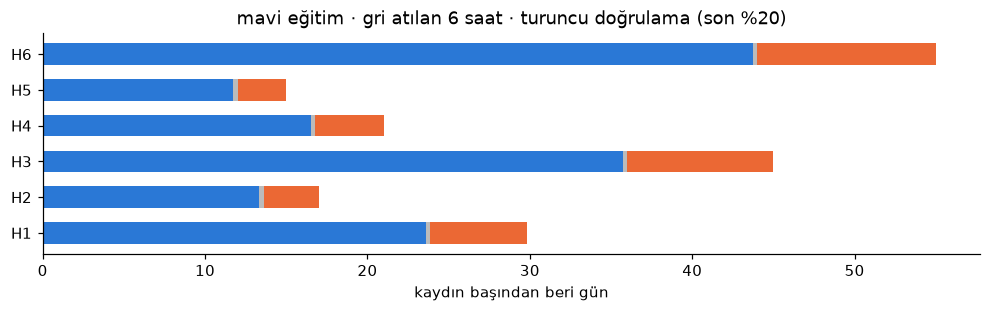

H1 eğitimin sonu → doğrulamanın başı: 0 days 06:00:10
H2 eğitimin sonu → doğrulamanın başı: 0 days 06:00:10
H3 eğitimin sonu → doğrulamanın başı: 0 days 06:00:10
H4 eğitimin sonu → doğrulamanın başı: 0 days 06:00:10
H5 eğitimin sonu → doğrulamanın başı: 0 days 06:00:10
H6 eğitimin sonu → doğrulamanın başı: 0 days 06:00:10


In [3]:
fig, ax = plt.subplots(figsize=(11, 2.6)); renk = {"train": "#2A78D6", "gap": "#BBBBBB", "val": "#EB6834"}
for k, h in enumerate(HOMES):
    ts = LAB[h]["ts"]; gun = ((ts - ts.iloc[0]).dt.total_seconds() / 86400).to_numpy()   # evin ilk gününden beri geçen gün
    for part in ["train", "gap", "val"]:
        g = gun[P[h] == part]; ax.barh(k, g.max() - g.min(), left=g.min(), color=renk[part], height=0.6)
ax.set_yticks(range(6), HOMES); ax.set_xlabel("kaydın başından beri gün")
ax.set_title("mavi eğitim · gri atılan 6 saat · turuncu doğrulama (son %20)"); plt.show()
for h in HOMES:
    ts = LAB[h]["ts"]; print(h, "eğitimin sonu → doğrulamanın başı:", ts[P[h] == "val"].min() - ts[P[h] == "train"].max())

## 8.3 Sızıntıyı ölçmek: "komşuyu kopyala" hilesi

Hiçbir şey öğrenmeyen bir hile: test penceresine aynı evde zamanca en yakın **eğitim** penceresinin etiketini söyle. Hile
yüksek puan alıyorsa bölme kopyaya izin veriyor demektir (sızıntı).

In [4]:
leakage_table()

,Bölme,Değerlendirilen pencere,Komşusu eğitimde (%),'Komşuyu kopyala' hilesinin doğruluğu (%)
0,Rastgele %80/%20 (yapmadığımız),262453,95.99,99.95
1,"Bizim doğrulama (son %20, 6 sa boşluk)",315953,0.00,57.76
2,Bizim test (leave-one-home-out),1311925,0.00,uygulanamaz: test evinde eğitim penceresi yok


**Neden bizde sıfır? Tasarım gereği.**
- *Test:* test evinin hiçbir penceresi eğitimde yok; hile aynı evde komşu arıyor ve bulamıyor.
- *Doğrulama:* aradaki 6 saat atıldığı için en yakın eğitim penceresi 6 saat 10 saniye uzakta; 10 saniyelik komşu olamaz.
- Doğrulamadaki ~%58 sızıntı değil: 6 saat önceki durumu söylemek kadar, yani günlük rutin. Rastgele tahmin %33 verirdi.

Rastgele bölmede ise test pencerelerinin ~%96'sının ikizi eğitimde; hile %99,95 alıyor. Rastgele bölmeyle eğitilen her model
sahte biçimde mükemmel görünürdü.

## 8.4 Modele hazır örnek

`dataset.window(ev, i)` tek bir örneği modelin göreceği biçimde döndürür. Hub sayısı evden eve değiştiği için (4–5) kutular
5 sabit yuvaya dizilir; olmayan yuva maskelenir. Ön işleme okunurken uygulanır: kare /255, ses hub içi z, ortam temizlik +
doldurma + hub içi z.

In [5]:
from dataset import window
w = window("H1", 100_000)
pd.DataFrame([(k, str(np.shape(v)), getattr(v, "dtype", type(v).__name__)) for k, v in w.items()], columns=["anahtar", "şekil", "tip"])

,anahtar,şekil,tip
0,home,(),str
1,index,(),int
2,ts,(),str
3,hubs,"(5,)",list
4,img,"(5, 32, 32)",float32
5,aud,"(5, 800)",float32
6,env,"(5, 5)",float32
7,mask_img,"(5,)",bool
8,mask_aud,"(5,)",bool
9,mask_env,"(5, 5)",bool


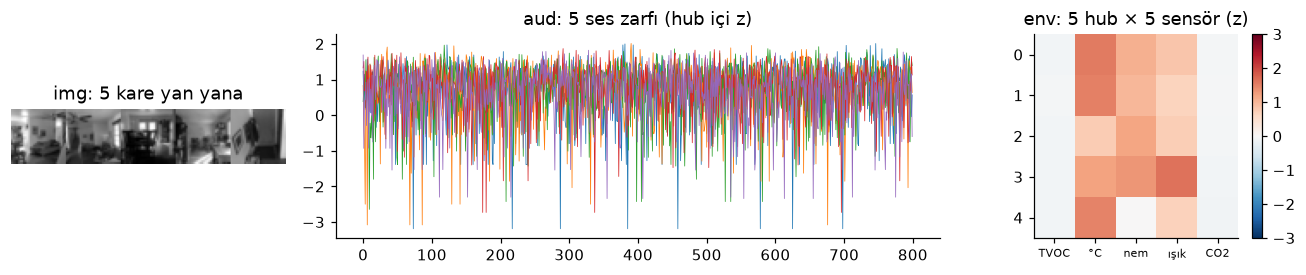

zaman: 2019-12-07 13:46:40 | etiket y = 2 (4 kişi)


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(12, 2.6), gridspec_kw={"width_ratios": [1, 2.2, 1]})
ax[0].imshow(np.hstack(w["img"]), cmap="gray"); ax[0].set_title("img: 5 kare yan yana"); ax[0].axis("off")
for k in range(5): ax[1].plot(w["aud"][k], lw=0.5)
ax[1].set_title("aud: 5 ses zarfı (hub içi z)")
im = ax[2].imshow(w["env"], cmap="RdBu_r", vmin=-3, vmax=3); ax[2].set_title("env: 5 hub × 5 sensör (z)")
ax[2].set_xticks(range(5), ["TVOC", "°C", "nem", "ışık", "CO2"], fontsize=7); plt.colorbar(im, ax=ax[2], fraction=0.046)
plt.tight_layout(); plt.show()
print("zaman:", pd.Timestamp(LAB["H1"]["ts"][100_000]), "| etiket y =", w["y"], f"({w['number']} kişi)")

## 8.5 Mini-batch: modelin bir adımda gördüğü

Eğitimde örnekler gruplar (batch) hâlinde verilir. 8 pencereyi üst üste koyunca her anahtar bir boyut kazanır.

In [7]:
rng = np.random.default_rng(0); idx = rng.choice(len(LAB["H3"]), 8, replace=False)
batch = [window("H3", int(i)) for i in idx]
B = {k: np.stack([b[k] for b in batch]) for k in ["img", "aud", "env", "mask_img", "mask_aud", "mask_env", "y"]}
for k, v in B.items(): print(f"{k:9s} {str(v.shape):18s} {v.dtype}")

img       (8, 5, 32, 32)     float32
aud       (8, 5, 800)        float32
env       (8, 5, 5)          float32
mask_img  (8, 5)             bool
mask_aud  (8, 5)             bool
mask_env  (8, 5, 5)          bool
y         (8,)               int64


`img (8, 5, 32, 32)` = 8 örnek × 5 kutu × 32×32 kare. Final modeli bu sözlüğü alacak: görüntü için küçük CNN, ses için
1 boyutlu CNN, ortam için MLP; üçünün çıktısı maskelerle birleştirilip (ara füzyon) 3 sınıftan biri tahmin edilecek.

## 8.6 Sınıf ağırlıkları (gerekirse)

Eğitim turunun kendi sayılarından hesaplanır (test evine bakılmaz). Örnek: tur 1 (test H1).

In [8]:
f = next(folds())
y = np.concatenate([LAB[h]["cls"].to_numpy()[P[h] == "train"] for h in f["train"]])
n = np.bincount(y, minlength=3); w8 = n.sum() / (3 * n)
pd.DataFrame({"sınıf": CLS, "eğitim sayısı": n, "pay %": (100 * n / n.sum()).round(1), "ağırlık": w8.round(2)}).set_index("sınıf")

,eğitim sayısı,pay %,ağırlık
sınıf,,,
0 kişi,244351,31.4,1.06
1 kişi,326681,41.9,0.79
2+ kişi,207864,26.7,1.25


Ağırlıklar 1'e yakın: eğitim verisi zaten dengeli, ağırlıklandırma şart değil.